# Figure 6 — Deployment schematic: regime-routed model selection
iMeta-style closing schematic: the protocol measures the observable regime
(obs_agreement, perturbation density) at prediction time and routes model
choice accordingly — the paper's actionable contribution in one panel.

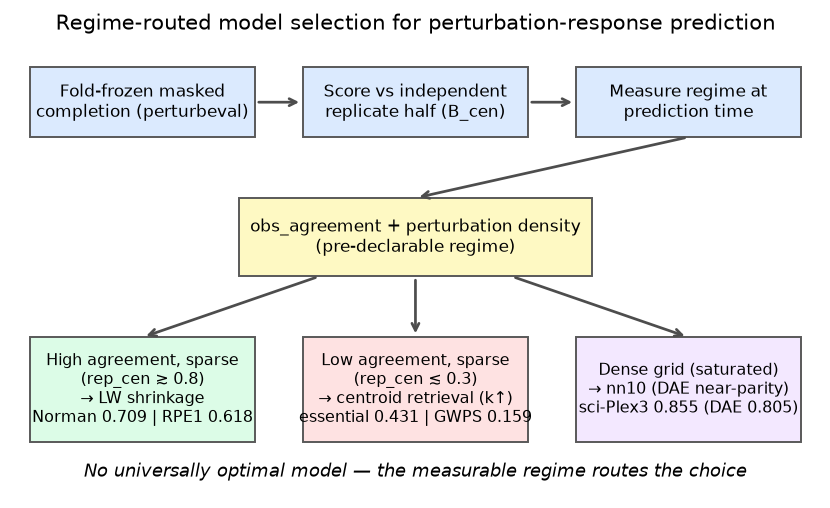

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RES = os.path.join("..", "..", "results")
FIG = os.path.join("..", "..", "figures")
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 300,
                     "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
MODELS = ["lw", "svd20", "moppca5", "nn10", "nn50"]
MODEL_LABELS = {"lw": "LW shrinkage", "svd20": "SVD-20",
                "moppca5": "moPPCA-5", "nn10": "centroid-10",
                "nn50": "centroid-50"}
CONTEXTS = [
    ("K562 essential", "j22_k562_foldfrozen_centroid.csv"),
    ("K562 GWPS", "j22_k562_gwps_foldfrozen_centroid.csv"),
    ("Norman", "j49_norman_foldfrozen.csv"),
    ("RPE1", "j49_rpe1_foldfrozen.csv"),
    ("sci-Plex3", "j49_sciplex3.csv"),
]
def load_ctx(name, fname):
    df = pd.read_csv(os.path.join(RES, fname))
    df["context"] = name
    return df

fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.axis("off")

def box(x, y, w, h, txt, fc, fs=8.5, tc="black"):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=fc, ec="0.35"))
    ax.text(x + w/2, y + h/2, txt, ha="center", va="center",
            fontsize=fs, color=tc)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="0.3", lw=1.4))

# protocol spine (top)
box(0.02, 0.78, 0.28, 0.16, "Fold-frozen masked\ncompletion (perturbeval)", "#dbeafe")
box(0.36, 0.78, 0.28, 0.16, "Score vs independent\nreplicate half (B_cen)", "#dbeafe")
box(0.70, 0.78, 0.28, 0.16, "Measure regime at\nprediction time", "#dbeafe")
arrow(0.30, 0.86, 0.36, 0.86); arrow(0.64, 0.86, 0.70, 0.86)

# regime router (middle)
box(0.28, 0.46, 0.44, 0.18,
    "obs_agreement + perturbation density\n(pre-declarable regime)", "#fef9c3")
arrow(0.84, 0.78, 0.50, 0.64)

# three routing outcomes (bottom)
box(0.02, 0.08, 0.28, 0.24,
    "High agreement, sparse\n(rep_cen ≳ 0.8)\n→ LW shrinkage\nNorman 0.709 | RPE1 0.618", "#dcfce7", fs=8)
box(0.36, 0.08, 0.28, 0.24,
    "Low agreement, sparse\n(rep_cen ≲ 0.3)\n→ centroid retrieval (k↑)\nessential 0.431 | GWPS 0.159", "#fee2e2", fs=8)
box(0.70, 0.08, 0.28, 0.24,
    "Dense grid (saturated)\n→ nn10 (DAE near-parity)\nsci-Plex3 0.855 (DAE 0.805)", "#f3e8ff", fs=8)
arrow(0.38, 0.46, 0.16, 0.32); arrow(0.50, 0.46, 0.50, 0.32); arrow(0.62, 0.46, 0.84, 0.32)

ax.text(0.5, 0.0, "No universally optimal model — the measurable regime routes the choice",
        ha="center", fontsize=9.5, style="italic")
ax.set_title("Regime-routed model selection for perturbation-response prediction",
             fontsize=11)
ax.set_xlim(0, 1); ax.set_ylim(-0.04, 1)
fig.savefig(os.path.join(FIG, "fig6_decision_schematic.png"), bbox_inches="tight")
plt.show()
